# 02. Mô tả chuỗi và bóc tách

**Mục tiêu:** nhìn hình dạng của chuỗi CPI và tách nó thành *xu hướng*, *mùa vụ* và *phần còn lại*. Đây là phần **mô tả** (Mục 4.1 đến 4.3 của báo cáo), không phân tích nguyên nhân.

**Hai chuỗi ta dùng** (đều lấy từ `data/processed/cpi_monthly_clean.csv`):
- `index`: chỉ số CPI liên hoàn, kỳ gốc 01/2006 = 100.
- `pct`: % thay đổi so với tháng trước (bằng `mom − 100`).

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Nạp dữ liệu

In [2]:
df = pd.read_csv("../data/processed/cpi_monthly_clean.csv", parse_dates=["date"])
df.head()

,date,mom,pct,index
0,2006-01-01,101.2,1.2,100.000000
1,2006-02-01,102.1,2.1,102.100000
2,2006-03-01,99.5,-0.5,101.589500
3,2006-04-01,100.2,0.2,101.792679
4,2006-05-01,100.6,0.6,102.403435


## 2. Hình dạng chung của hai chuỗi

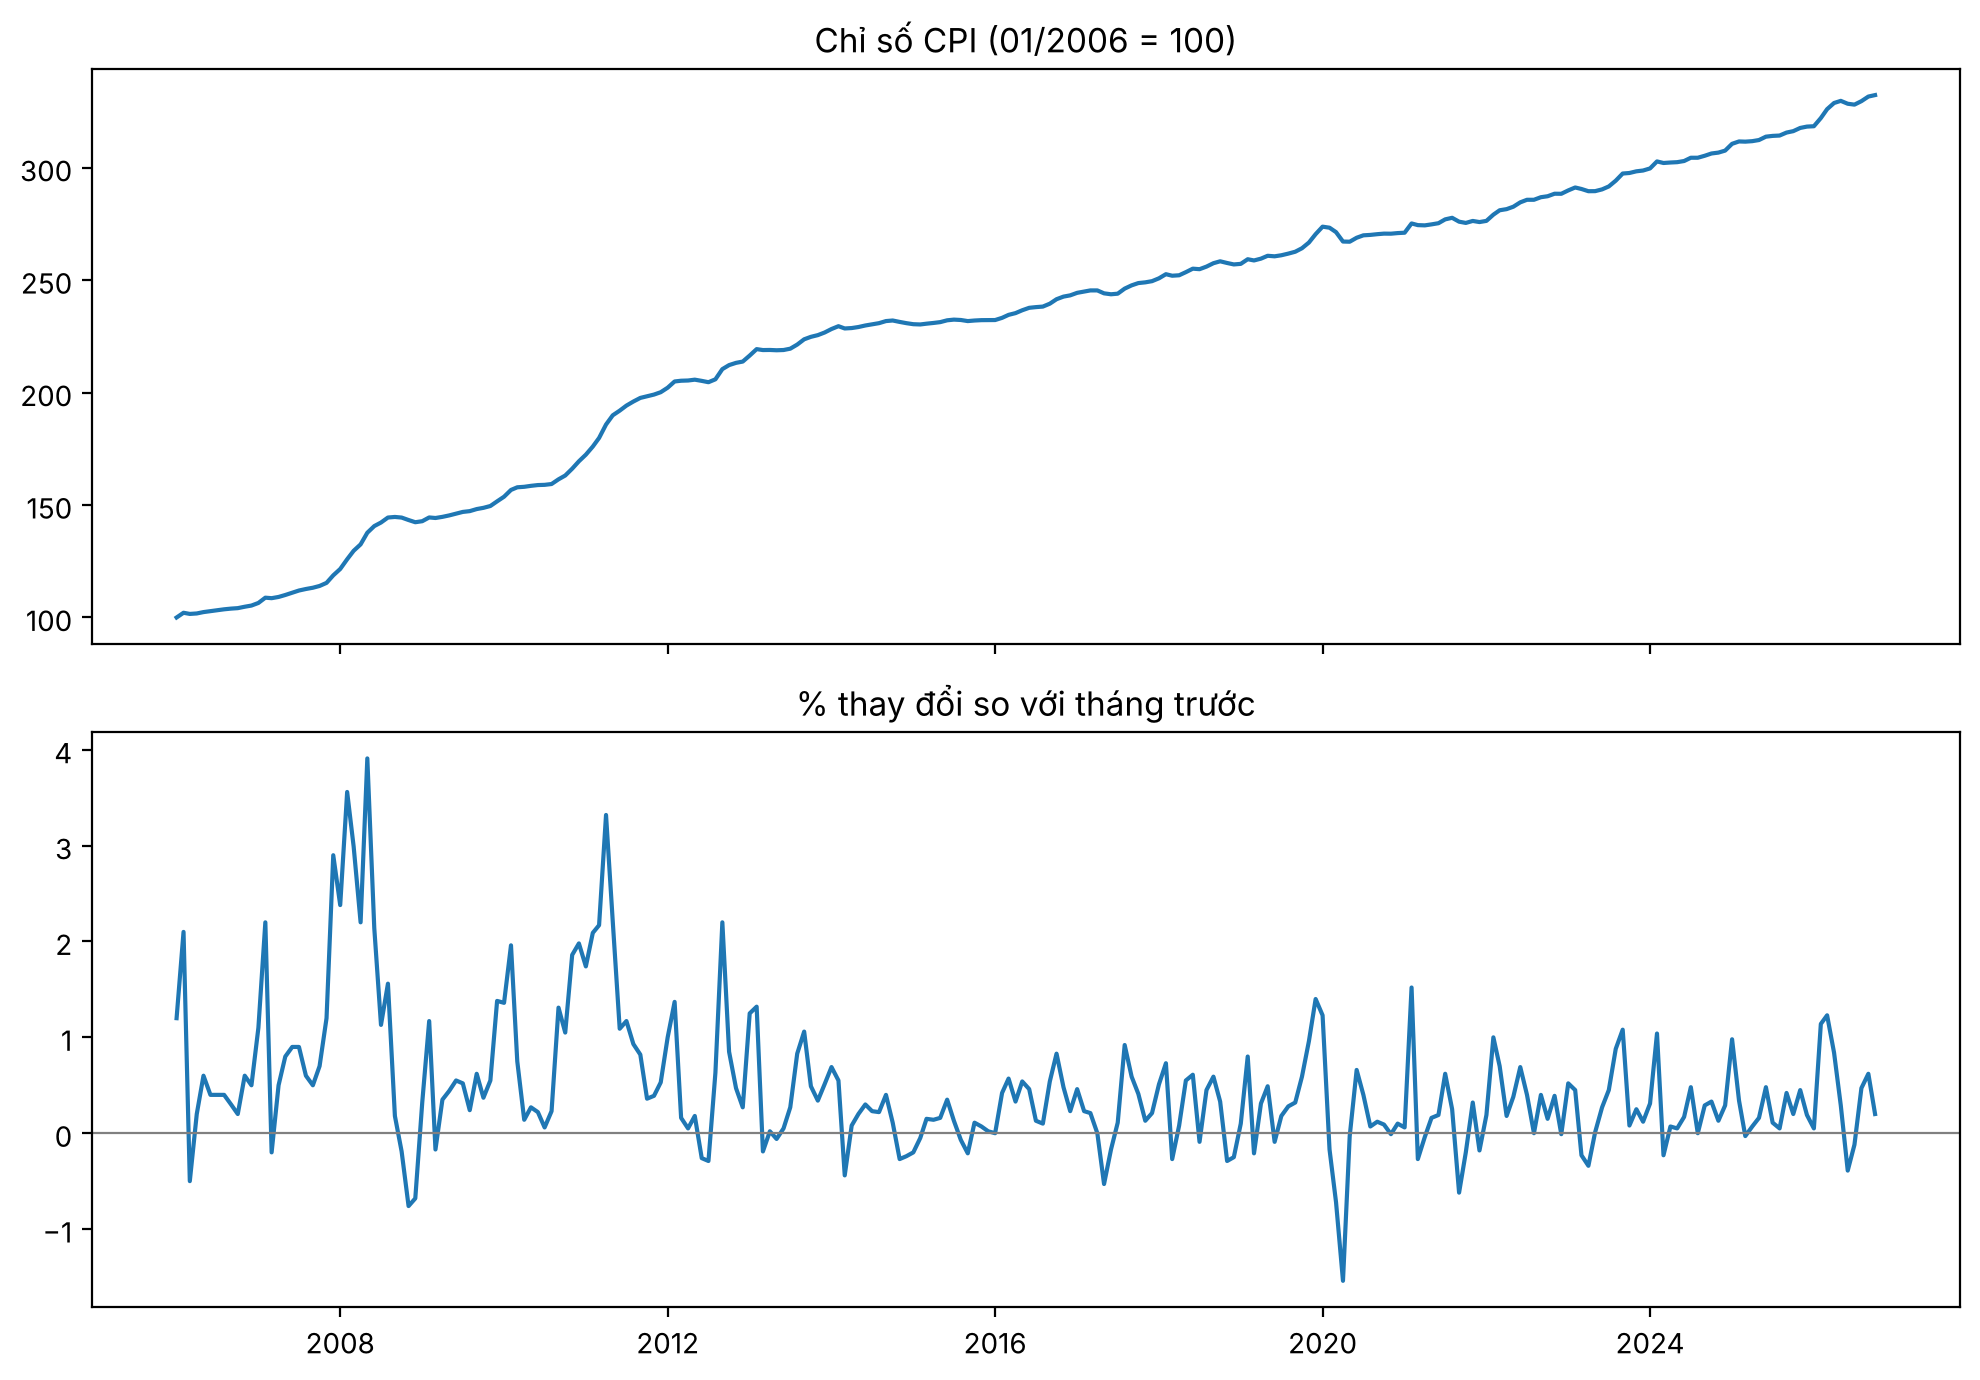

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(df["date"], df["index"])
axes[0].set_title("Chỉ số CPI (01/2006 = 100)")

axes[1].plot(df["date"], df["pct"])
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("% thay đổi so với tháng trước")

plt.tight_layout()
plt.show()

In [4]:
i_max, i_min = df["pct"].idxmax(), df["pct"].idxmin()
print("Chỉ số đầu / cuối: %.1f -> %.1f" % (df["index"].iloc[0], df["index"].iloc[-1]))
print("pct lớn nhất : %.2f%% (%s)" % (df["pct"].max(), df.loc[i_max, "date"].strftime("%m/%Y")))
print("pct nhỏ nhất : %.2f%% (%s)" % (df["pct"].min(), df.loc[i_min, "date"].strftime("%m/%Y")))

Chỉ số đầu / cuối: 100.0 -> 332.3
pct lớn nhất : 3.91% (05/2008)
pct nhỏ nhất : -1.54% (04/2020)


**Nhận xét:**
- **Chỉ số** đi lên liên tục, tức có *xu hướng* rõ rệt.
- **% thay đổi** không có xu hướng mà dao động trong một khoảng, và *biến động mạnh trước khoảng năm 2013, êm hơn sau đó*.

Hai chuỗi này cư xử rất khác nhau, nên các mô hình ở notebook 03 cũng cho kết quả khác nhau trên từng chuỗi.

## 3. Bóc tách xu hướng và mùa vụ

Ta coi chuỗi là tổng của ba phần:

`chuỗi = xu hướng + mùa vụ + phần còn lại`

- **Xu hướng:** trung bình trượt 12 tháng (làm phẳng các dao động ngắn hạn).
- **Mùa vụ:** sau khi bỏ xu hướng, lấy trung bình theo từng tháng trong năm (tháng 1, tháng 2, ...) qua các năm.
- **Phần còn lại:** phần chưa giải thích được.

Ta bóc tách chuỗi **`pct`**, vì mùa vụ dễ thấy ở chuỗi không có xu hướng đi lên. Hàm nằm trong `src/cpi_forecast/analysis/decomposition.py`.

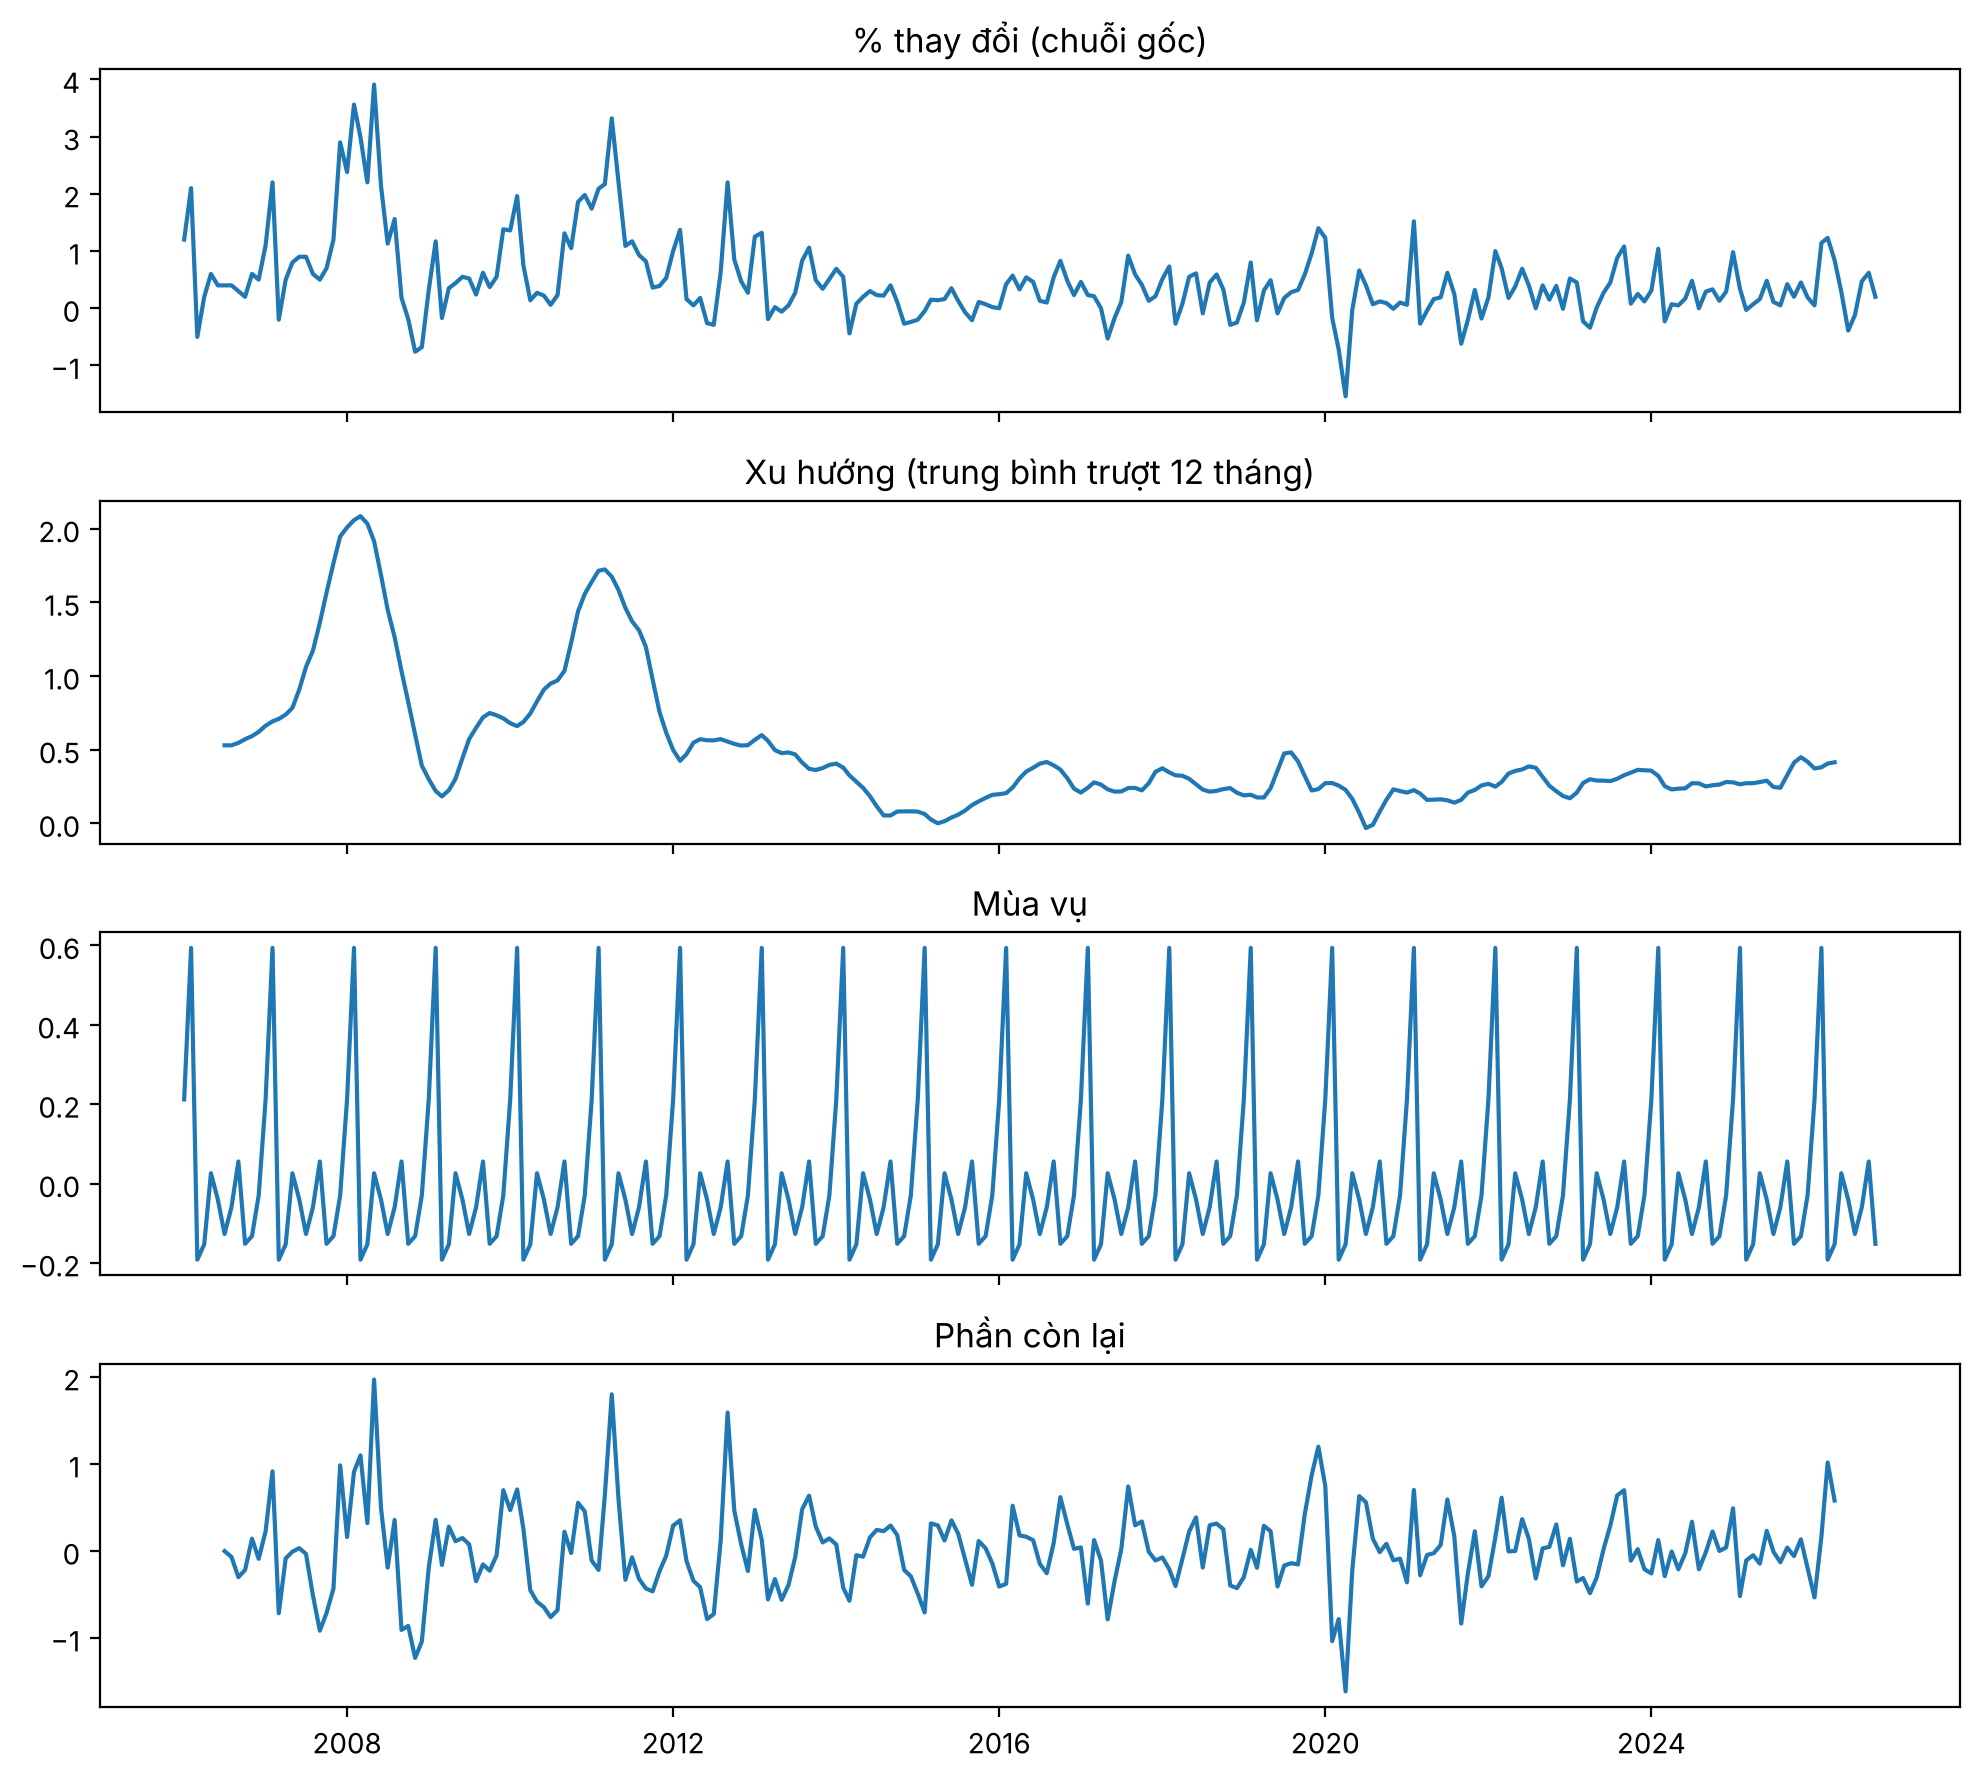

{'T1': np.float64(0.21), 'T2': np.float64(0.59), 'T3': np.float64(-0.19), 'T4': np.float64(-0.15), 'T5': np.float64(0.03), 'T6': np.float64(-0.04), 'T7': np.float64(-0.13), 'T8': np.float64(-0.06), 'T9': np.float64(0.06), 'T10': np.float64(-0.15), 'T11': np.float64(-0.13), 'T12': np.float64(-0.03)}


In [5]:
from cpi_forecast.analysis.decomposition import decompose

d = decompose(df["pct"].to_numpy(), period=12)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(df["date"], df["pct"]);        axes[0].set_title("% thay đổi (chuỗi gốc)")
axes[1].plot(df["date"], d["xu_huong"]);    axes[1].set_title("Xu hướng (trung bình trượt 12 tháng)")
axes[2].plot(df["date"], d["mua_vu"]);      axes[2].set_title("Mùa vụ")
axes[3].plot(df["date"], d["con_lai"]);     axes[3].set_title("Phần còn lại")
plt.tight_layout(); plt.show()

# Chỉ số mùa vụ theo từng tháng (12 giá trị)
thang = ["T1","T2","T3","T4","T5","T6","T7","T8","T9","T10","T11","T12"]
print(dict(zip(thang, d["mua_vu"][:12].round(2))))

In [6]:
print("Độ lệch chuẩn của mùa vụ     : %.2f" % np.std(d["mua_vu"]))
print("Độ lệch chuẩn của phần còn lại: %.2f" % np.nanstd(d["con_lai"]))

Độ lệch chuẩn của mùa vụ     : 0.21
Độ lệch chuẩn của phần còn lại: 0.47


**Cách đọc 4 hình (từ trên xuống):**
1. Chuỗi gốc.
2. **Xu hướng:** có hai "gò" cao ở khoảng 2008 và 2011, rồi thấp và phẳng từ khoảng 2013. Hai đầu chuỗi ngắn hơn 6 tháng vì trung bình trượt cần nhìn 6 tháng mỗi bên (không phải lỗi).
3. **Mùa vụ:** 12 con số lặp lại y hệt mỗi năm. Tháng 2 nổi bật nhất (+0,59 điểm %), tháng 1 hơi cao (+0,21), các tháng còn lại quanh 0.
4. **Phần còn lại:** vẫn dao động mạnh ở các giai đoạn 2008, 2011 và 2020, tức ba giai đoạn này không giải thích được bằng xu hướng hay mùa vụ.

**Kết luận mô tả:** mùa vụ có thật nhưng chỉ giải thích được một phần (độ lệch chuẩn 0,21 so với 0,47 của phần còn lại). Việc tháng 1 và 2 cao thường được liên hệ với dịp Tết; ở đây ta chỉ mô tả, không phân tích nhân quả.